In [1]:
from pipeline_stable_diffusion_3_inpaint import StableDiffusion3InpaintPipeline
from diffusers import AutoPipelineForInpainting, StableDiffusionInpaintPipeline, EulerDiscreteScheduler, DPMSolverMultistepScheduler
from diffusers.utils import load_image
import torch
import os, sys
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
import cv2
from tqdm import tqdm

from huggingface_hub import login
login()

# Add the project root directory to sys.path
project_root = os.path.abspath('..')  # Adjust this path if needed
sys.path.append(project_root)

from utils import load_images_and_combine
from utils import mask_on_image

KeyboardInterrupt: 

In [ ]:
device = "mps" if torch.backends.mps.is_available() else "cuda:0"
print(f"Using device: {device}")

model_name="diffusers/stable-diffusion-xl-inpainting"

model_dict = {"diffusers/stable-diffusion-xl-1.0-inpainting-0.1":
                AutoPipelineForInpainting.from_pretrained("diffusers/stable-diffusion-xl-1.0-inpainting-0.1", torch_dtype=torch.float16, variant="fp16"),
              "runwayml/stable-diffusion-inpainting":
                StableDiffusionInpaintPipeline.from_pretrained("runwayml/stable-diffusion-inpainting", revision="fp16", torch_dtype=torch.float16),
              "stabilityai/stable-diffusion-2-inpainting": 
                StableDiffusionInpaintPipeline.from_pretrained("stabilityai/stable-diffusion-2-inpainting",torch_dtype=torch.float16),
              #"stablityai/stable-diffusion-3-medium-diffusers":
              #  StableDiffusion3InpaintPipeline.from_pretrained("stablityai/stable-diffusion-3-medium-diffusers",torch_dtype=torch.float16)
              }

pipe = model_dict["diffusers/stable-diffusion-xl-1.0-inpainting-0.1"]
pipe = pipe.to(device)
pipe.enable_attention_slicing() # Recommended if your computer has < 64 GB of RAM

#pipe2 = model_dict["runwayml/stable-diffusion-inpainting"]
#pipe2 = pipe2.to(device)
#pipe2.enable_attention_slicing() # Recommended if your computer has < 64 GB of RAM

#pipe3 = model_dict["stabilityai/stable-diffusion-2-inpainting"]
#pipe3 = pipe3.to(device)
#pipe3.enable_attention_slicing() # Recommended if your computer has < 64 GB of RAM

#pipe4 = model_dict["diffusers/stable-diffusion-xl-inpainting"]
#pipe4 = pipe4.to(device)
#pipe4.enable_attention_slicing() # Recommended if your computer has < 64 GB of RAM

generator = torch.Generator(device).manual_seed(0)

Using device: cuda:0


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

The config attributes {'decay': 0.9999, 'inv_gamma': 1.0, 'min_decay': 0.0, 'optimization_step': 37000, 'power': 0.6666666666666666, 'update_after_step': 0, 'use_ema_warmup': False} were passed to UNet2DConditionModel, but are not expected and will be ignored. Please verify your config.json configuration file.
safety_checker/model.safetensors not found


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

An error occurred while trying to fetch /common-repos/LMs/hub/models--runwayml--stable-diffusion-inpainting/snapshots/afeee10def38be19995784bcc811882409d066e5/unet: Error no file named diffusion_pytorch_model.safetensors found in directory /common-repos/LMs/hub/models--runwayml--stable-diffusion-inpainting/snapshots/afeee10def38be19995784bcc811882409d066e5/unet.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.
An error occurred while trying to fetch /common-repos/LMs/hub/models--runwayml--stable-diffusion-inpainting/snapshots/afeee10def38be19995784bcc811882409d066e5/vae: Error no file named diffusion_pytorch_model.safetensors found in directory /common-repos/LMs/hub/models--runwayml--stable-diffusion-inpainting/snapshots/afeee10def38be19995784bcc811882409d066e5/vae.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

In [ ]:
def image_frequencies(image):  
    # image to numpy
    image = np.array(image)
    
    # Split the image into its respective color channels
    channels = cv2.split(image)
    channel_colors = ['Blue', 'Green', 'Red']
    channel_data = {}

    for idx, channel in enumerate(channels):
        unique, counts = np.unique(channel, return_counts=True)
        frequencies = dict(zip(unique, counts))
        channel_data[channel_colors[idx]] = frequencies

    # Plot the histograms for each channel
    plt.figure(figsize=(15, 5))
    for idx, (color, frequencies) in enumerate(channel_data.items()):
        plt.subplot(1, 3, idx+1)
        plt.bar(frequencies.keys(), frequencies.values(), color=color.lower(), width=1.0, edgecolor='black')
        plt.title(f'{color} Channel Pixel Intensity Frequency')
        plt.xlabel('Pixel Intensity')
        plt.ylabel('Frequency')
        plt.xlim([0, 255])
    plt.tight_layout()
    plt.show()

In [ ]:
def plot_grid(figures, num_cols=3, with_token=False, save_path=None):
    # Define the number of columns for the grid
    num_rows = (len(figures) + num_cols - 1) // num_cols  # Calculate the number of rows needed
    
    # Create a figure and a set of subplots
    if num_cols>4: 
        fig, axs = plt.subplots(num_rows, num_cols, figsize=(15, 2 * num_rows))
    else:
        fig, axs = plt.subplots(num_rows, num_cols, figsize=(15, 5 * num_rows))

    # Flatten the axes array for easy iteration
    axs = axs.flatten()

    # Plot each figure in the grid
    for i, fig in enumerate(figures):
        if with_token is True:
            axs[i].imshow(fig[0]) 
            axs[i].axis('off')      # Turn off the axis
            axs[i].set_title(fig[1])    # add title to subplot
        else:
            axs[i].imshow(fig)  
            axs[i].axis('off')      # Turn off the axis


    # Turn off any remaining empty subplots
    for j in range(i + 1, len(axs)):
        axs[j].axis('off')

    if save_path is not None:
        plt.savefig(save_path)

    # Show the grid of figures
    plt.tight_layout()
    plt.show()

In [ ]:
def adjust_white_balance(tgt_img, ref_img):
    # Read the images
    tgt_img = np.array(tgt_img, dtype=np.float32)
    ref_img = np.array(ref_img, dtype=np.float32)
    
    if ref_img is None or tgt_img is None:
        raise ValueError("One or both of the images could not be loaded.")
    
    # Convert images from BGR to RGB (OpenCV uses BGR by default)
    ref_img_rgb = cv2.cvtColor(ref_img, cv2.COLOR_BGR2RGB)
    tgt_img_rgb = cv2.cvtColor(tgt_img, cv2.COLOR_BGR2RGB)
    
    # Compute the mean color for each channel (R, G, B)
    ref_mean = np.mean(ref_img_rgb, axis=(0, 1))
    tgt_mean = np.mean(tgt_img_rgb, axis=(0, 1))
    
    # Compute the shift needed for each channel
    shift = ref_mean - tgt_mean
    
    # Apply the color shift to the target image
    tgt_img_rgb_shifted = tgt_img_rgb + shift
    tgt_img_rgb_shifted = np.clip(tgt_img_rgb_shifted, 0, 255).astype(np.uint8)
    
    # Convert the image back to BGR
    tgt_img_bgr_shifted = cv2.cvtColor(tgt_img_rgb_shifted, cv2.COLOR_RGB2BGR)

    # Convert the adjusted numpy array back to a PIL image
    adjusted_image = Image.fromarray(tgt_img_bgr_shifted.astype(np.uint8))

    return adjusted_image


In [ ]:
datasets = {
    'ISIC2019': {
        'dataset_dir': 'ISIC2019',
        'confounder_dir': "patch",
        'no_confounder_dir': "no_patch",
        'custom_vocabulary': ['colorful patch', 'colorful sticker', 'colorful circle', 'colorful cutted circle'],
        #["colorful cutted circle", "colorful circle", "coloful sticker", "colorful patch", "part of colorful sticker", "part of colorful patch", "part of colorful circle", "colorful semicircle", "colorful ellipsoid", "coloful cutted ellipsoid"]
        'confidence_threshold': 0.0007
    },

    'Pascal_VOC07': {
        'dataset_dir': 'Pascal_VOC07',
        'confounder_dir': 'horse_watermark',
        'no_confounder_dir': 'horse_no_watermark',
        'custom_vocabulary': ['watermark', 'signature', 'timestamp', 'letters'],
        'confidence_threshold': 0.0001  
    },

    'DecoyMNIST': {
        'dataset_dir': 'DecoyMNIST',
        'confounder_dir': 'confounder',
        'no_confounder_dir': 'no_confounder',
        'custom_vocabulary': ['square', 'confounder', 'rectangle'],
        'confidence_threshold': 0.0001
    }
}

In [ ]:
# Load images
num_imgs = 100
dataset_key ='ISIC2019'# 'Pascal_VOC07' #
dataset = datasets[dataset_key]
images = load_images_and_combine(dir_path=f"/workspace/home/data/{dataset['dataset_dir']}/raw", confounder_dir=dataset['confounder_dir'], no_confounder_dir=dataset['no_confounder_dir'], num_imgs=num_imgs)
segmentation_masks = load_images_and_combine(dir_path=f"/workspace/home/data/{dataset['dataset_dir']}/seg", confounder_dir=dataset['confounder_dir'], no_confounder_dir=dataset['no_confounder_dir'], num_imgs=num_imgs)

In [ ]:
def run_instance(image, mask_image, prompt, save_path):
    mask_np = np.array(mask_image)
    
    # Define a kernel for the dilation operation
    kernel = np.ones((50, 50), np.uint8)
    
    # Perform the dilation operation
    dilated_mask_image = cv2.dilate(mask_np, kernel, iterations=3)

    # Convert the dilated images back to PIL images for display
    dilated_mask_image_pil = Image.fromarray(dilated_mask_image)

    # Resize the images (e.g., to half the original size)
    image_resized = image.resize((image.width // 3, image.height // 3))
    dilated_mask_image_resized = dilated_mask_image_pil.resize((dilated_mask_image_pil.width // 3, dilated_mask_image_pil.height // 3))
    mask_image_resized = mask_image.resize((mask_image.width // 3, mask_image.height // 3))

    #
    mask_on_img = mask_on_image(image_resized, dilated_mask_image_resized)
    
    # use dilated mask as mask
    mask_image = dilated_mask_image_pil

    #scheduler
    scheduler = DPMSolverMultistepScheduler.from_pretrained("stabilityai/stable-diffusion-xl-base-1.0", subfolder="scheduler", use_karras= True, algorithm_type="sde-dpmsolver++")
    pipe.scheduler = scheduler.from_pretrained("stabilityai/stable-diffusion-xl-base-1.0", subfolder="scheduler")
    


    def run_model(pipeline, image, mask_image, prompt, guidance_scales, strengths, iterations=1):
        image_original_size = image.size

        image = image.resize((1024, 1024))
        mask_image = mask_image.resize((1024, 1024))

        list_of_images = []

        for guidance_scale in guidance_scales:
            for strength in strengths:
                # Perform image inpainting
                for i in range(iterations):
                    image = pipeline(
                    prompt=prompt,
                    image=image,
                    mask_image=mask_image,
                    guidance_scale=guidance_scale,
                    num_inference_steps=25,  # steps between 15 and 30 work well for us
                    strength=strength,  # make sure to use `strength` below 1.0
                    generator=generator,
                    #padding_mask_crop=32,
                    seed=122
                    ).images[0]

                image = image.resize((1024, 1024))

                image_copy = image.copy().resize(image_original_size)

                list_of_images.append((image_copy, f'guidance_scale={guidance_scale},\n strength={strength}'))

        return list_of_images
    
    # empty white image to fill gap in grid
    white_image = Image.new('RGB', (image_resized.width, image_resized.height), (255, 255, 255))
    
    # Run per model
    guidance_scales = [8.0, 12.0]#, 16.0]
    strengths = [0.99, 1.0]
    iterations = 2
    list_of_images = [(image_resized, 'image'), 
                      (dilated_mask_image_resized, 'dilated mask'), 
                      (mask_on_img, 'mask on image'), 
                      #(white_image, ""),                      
                      #(white_image, ""),
                      #(white_image, ""),
                      ]
    list_of_images.extend(run_model(pipe, image, mask_image, prompt, [8.], [0.99], iterations))
    #list_of_images.extend(run_model(pipe4, image, mask_image, prompt, guidance_scales, strengths))
    #list_of_images.extend(run_model(pipe2, image, mask_image, prompt, guidance_scales, strengths, iterations))
    #list_of_images.extend(run_model(pipe3, image, mask_image, prompt, guidance_scales, strengths, iterations))

    #image_inpainted3_resized_wb = adjust_white_balance(image_inpainted3_resized, image_resized)


    # Display the resized images
    plot_grid(list_of_images, num_cols=3, save_path=save_path, with_token=True)
    # Image frequency evaluation
    #image_frequencies(image_resized)
    #image_frequencies(image_inpainted_resized)
    #image_frequencies(image_inpainted3_resized)
    #image_frequencies(image_inpainted3_resized_wb)





0it [00:00, ?it/s]

  0%|          | 0/24 [00:00<?, ?it/s]

  0%|          | 0/24 [00:00<?, ?it/s]

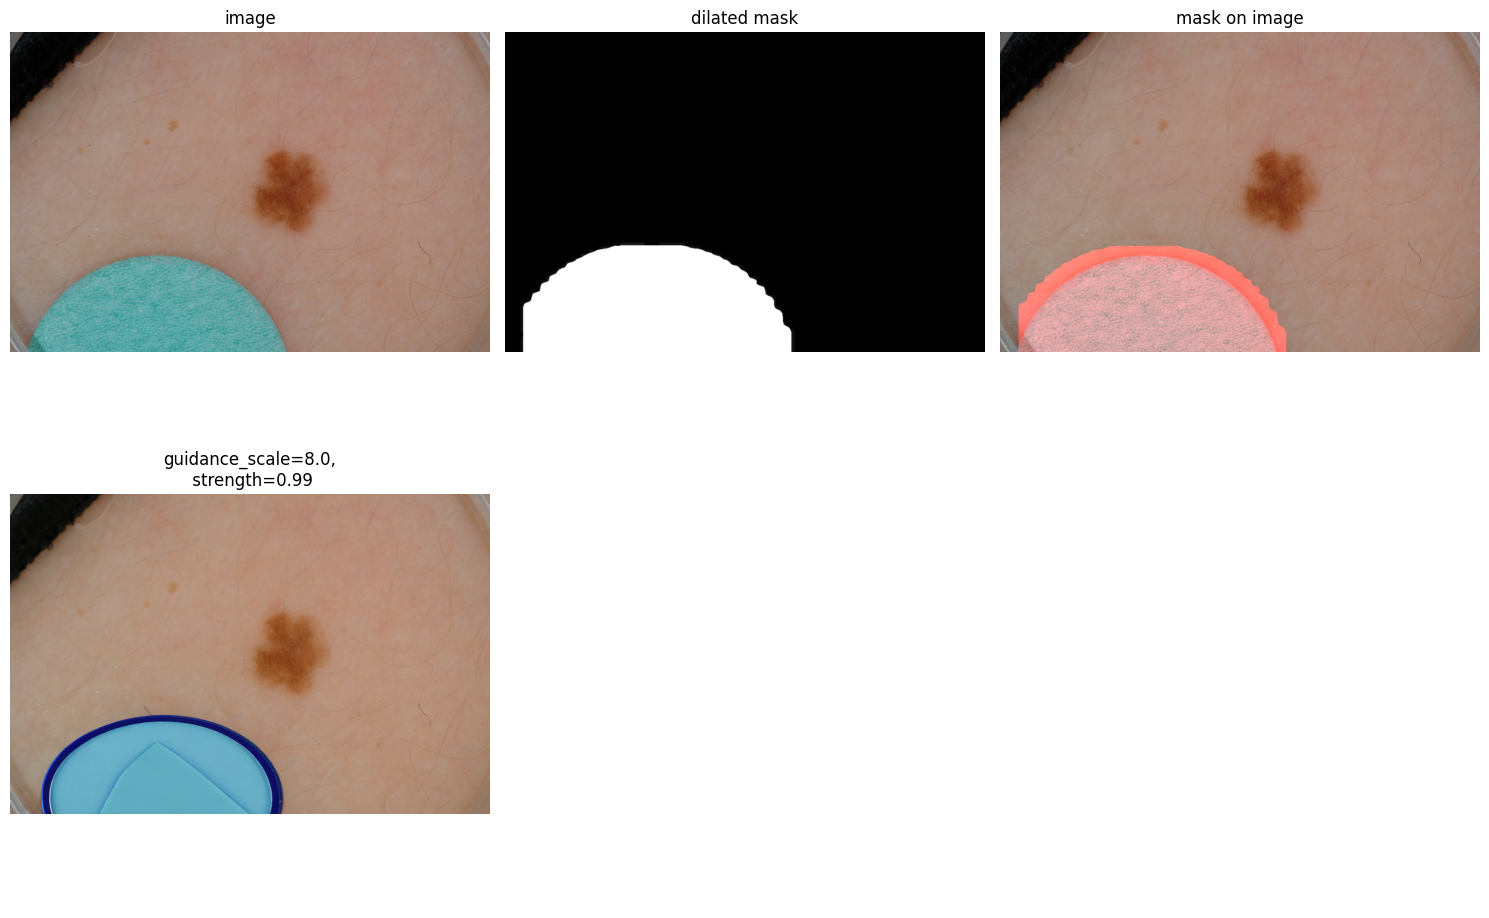

1it [00:22, 22.00s/it]

  0%|          | 0/24 [00:00<?, ?it/s]

1it [00:24, 24.69s/it]


KeyboardInterrupt: 

In [ ]:
prompt = ""
# "part of skin"
#"remove the confounder"
# ""
#"remove colorful patch"
#"lesion on skin"

for i, (image_dict, mask_dict) in enumerate(tqdm(zip(images[:num_imgs], segmentation_masks[:num_imgs]))):
  image = image_dict['image']
  meta_img = image_dict['meta']
  img_url = meta_img['file_path']

  mask = mask_dict['image']
  meta_mask = mask_dict['meta']
  mask_url = meta_mask['file_path']

  image = load_image(img_url)
  mask_image = load_image(mask_url).resize(image.size)


  output_dir = f"/workspace/home/outputfiles/{dataset['dataset_dir']}/inpainting/"
  os.makedirs(output_dir, exist_ok=True)
  file_name = meta_img['file_name'].split('.')[0]
  save_path = os.path.join(output_dir, f'{file_name}_[{prompt}].jpeg')

  run_instance(image, mask_image, prompt, save_path)